# 🏏 IPL Cricket Data Analysis – Exploratory Data Analysis (EDA)

## 1. Project Introduction

The Indian Premier League (IPL) is one of the most popular cricket tournaments in the world.

This project focuses on exploring IPL match data and ball-by-ball delivery data to understand team performance, player contributions, scoring patterns, toss decisions and match outcomes.

The analysis uses Python libraries such as Pandas, NumPy, Matplotlib and Seaborn to clean, analyze and visualize cricket data.

### Project Objectives

- Analyze IPL matches across different seasons.
- Identify the most successful teams.
- Study toss decisions and match results.
- Explore top batsmen and bowlers.
- Understand scoring patterns and match trends.
- Identify outliers and important insights.

### Datasets Used

1. `matches.csv` – Contains IPL match information.
2. `deliveries.csv` – Contains ball-by-ball match information.

### Tools and Technologies

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Jupyter Notebook

## 2. Importing Libraries and Loading the Dataset

This section imports the required Python libraries and loads the IPL matches and deliveries datasets into Pandas DataFrames.

The libraries will help us perform data manipulation, numerical calculations and graphical visualizations.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load IPL datasets
matches = pd.read_csv("matches.csv")
deliveries = pd.read_csv("deliveries.csv")

print("Matches Dataset:", matches.shape)
print("Deliveries Dataset:", deliveries.shape)

Matches Dataset: (1095, 20)
Deliveries Dataset: (260920, 17)


## 3. Initial Data Inspection

In this section, we will examine both IPL datasets to understand their structure and contents.

We will check the first few records, dataset dimensions, column names, data types and statistical summaries.

This step helps us understand the data before performing cleaning and analysis.

In [4]:
# Display first five records

print("IPL Matches Dataset")
display(matches.head())

print("IPL Deliveries Dataset")
display(deliveries.head())

IPL Matches Dataset


,id,season,city,date,match_type,player_of_match,venue,team1,team2,toss_winner,toss_decision,winner,result,result_margin,target_runs,target_overs,super_over,method,umpire1,umpire2
0,335982,2007/08,Bangalore,2008-04-18,League,BB McCullum,M Chinnaswamy Stadium,Royal Challengers Bangalore,Kolkata Knight Riders,Royal Challengers Bangalore,field,Kolkata Knight Riders,runs,140.0,223.0,20.0,N,NaN,Asad Rauf,RE Koertzen
1,335983,2007/08,Chandigarh,2008-04-19,League,MEK Hussey,"Punjab Cricket Association Stadium, Mohali",Kings XI Punjab,Chennai Super Kings,Chennai Super Kings,bat,Chennai Super Kings,runs,33.0,241.0,20.0,N,NaN,MR Benson,SL Shastri
2,335984,2007/08,Delhi,2008-04-19,League,MF Maharoof,Feroz Shah Kotla,Delhi Daredevils,Rajasthan Royals,Rajasthan Royals,bat,Delhi Daredevils,wickets,9.0,130.0,20.0,N,NaN,Aleem Dar,GA Pratapkumar
3,335985,2007/08,Mumbai,2008-04-20,League,MV Boucher,Wankhede Stadium,Mumbai Indians,Royal Challengers Bangalore,Mumbai Indians,bat,Royal Challengers Bangalore,wickets,5.0,166.0,20.0,N,NaN,SJ Davis,DJ Harper
4,335986,2007/08,Kolkata,2008-04-20,League,DJ Hussey,Eden Gardens,Kolkata Knight Riders,Deccan Chargers,Deccan Chargers,bat,Kolkata Knight Riders,wickets,5.0,111.0,20.0,N,NaN,BF Bowden,K Hariharan


IPL Deliveries Dataset


,match_id,inning,batting_team,bowling_team,over,ball,batter,bowler,non_striker,batsman_runs,extra_runs,total_runs,extras_type,is_wicket,player_dismissed,dismissal_kind,fielder
0,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,1,SC Ganguly,P Kumar,BB McCullum,0,1,1,legbyes,0,NaN,NaN,NaN
1,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,2,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN
2,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,3,BB McCullum,P Kumar,SC Ganguly,0,1,1,wides,0,NaN,NaN,NaN
3,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,4,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN
4,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,5,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN


In [5]:
# Check number of rows and columns

print("Matches Dataset Shape:", matches.shape)
print("Deliveries Dataset Shape:", deliveries.shape)

Matches Dataset Shape: (1095, 20)
Deliveries Dataset Shape: (260920, 17)


In [6]:
# Display column names

print("Matches Columns:")
print(matches.columns.tolist())

print("\nDeliveries Columns:")
print(deliveries.columns.tolist())

Matches Columns:
['id', 'season', 'city', 'date', 'match_type', 'player_of_match', 'venue', 'team1', 'team2', 'toss_winner', 'toss_decision', 'winner', 'result', 'result_margin', 'target_runs', 'target_overs', 'super_over', 'method', 'umpire1', 'umpire2']

Deliveries Columns:
['match_id', 'inning', 'batting_team', 'bowling_team', 'over', 'ball', 'batter', 'bowler', 'non_striker', 'batsman_runs', 'extra_runs', 'total_runs', 'extras_type', 'is_wicket', 'player_dismissed', 'dismissal_kind', 'fielder']


In [7]:
# Dataset information

print("Matches Dataset Information")
matches.info()

print("\nDeliveries Dataset Information")
deliveries.info()

Matches Dataset Information
<class 'pandas.DataFrame'>
RangeIndex: 1095 entries, 0 to 1094
Data columns (total 20 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id               1095 non-null   int64  
 1   season           1095 non-null   str    
 2   city             1044 non-null   str    
 3   date             1095 non-null   str    
 4   match_type       1095 non-null   str    
 5   player_of_match  1090 non-null   str    
 6   venue            1095 non-null   str    
 7   team1            1095 non-null   str    
 8   team2            1095 non-null   str    
 9   toss_winner      1095 non-null   str    
 10  toss_decision    1095 non-null   str    
 11  winner           1090 non-null   str    
 12  result           1095 non-null   str    
 13  result_margin    1076 non-null   float64
 14  target_runs      1092 non-null   float64
 15  target_overs     1092 non-null   float64
 16  super_over       1095 non-null   str    
 1

In [8]:
# Statistical summary

display(matches.describe(include="all"))
display(deliveries.describe(include="all"))

,id,season,city,date,match_type,player_of_match,venue,team1,team2,toss_winner,toss_decision,winner,result,result_margin,target_runs,target_overs,super_over,method,umpire1,umpire2
count,1.095000e+03,1095,1044,1095,1095,1090,1095,1095,1095,1095,1095,1090,1095,1076.000000,1092.000000,1092.000000,1095,21,1095,1095
unique,NaN,17,36,823,8,291,58,19,19,19,2,19,4,NaN,NaN,NaN,2,1,62,62
top,NaN,2013,Mumbai,2008-04-19,League,AB de Villiers,Eden Gardens,Royal Challengers Bangalore,Mumbai Indians,Mumbai Indians,field,Mumbai Indians,wickets,NaN,NaN,NaN,N,D/L,AK Chaudhary,S Ravi
freq,NaN,76,173,2,1029,25,77,135,138,143,704,144,578,NaN,NaN,NaN,1081,21,115,83
mean,9.048283e+05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,17.259294,165.684066,19.759341,NaN,NaN,NaN,NaN
std,3.677402e+05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,21.787444,33.427048,1.581108,NaN,NaN,NaN,NaN
min,3.359820e+05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,43.000000,5.000000,NaN,NaN,NaN,NaN
25%,5.483315e+05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.000000,146.000000,20.000000,NaN,NaN,NaN,NaN
50%,9.809610e+05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8.000000,166.000000,20.000000,NaN,NaN,NaN,NaN
75%,1.254062e+06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,20.000000,187.000000,20.000000,NaN,NaN,NaN,NaN


,match_id,inning,batting_team,bowling_team,over,ball,batter,bowler,non_striker,batsman_runs,extra_runs,total_runs,extras_type,is_wicket,player_dismissed,dismissal_kind,fielder
count,2.609200e+05,260920.000000,260920,260920,260920.000000,260920.000000,260920,260920,260920,260920.000000,260920.000000,260920.000000,14125,260920.000000,12950,12950,9354
unique,NaN,NaN,19,19,NaN,NaN,673,530,663,NaN,NaN,NaN,5,NaN,629,10,607
top,NaN,NaN,Mumbai Indians,Mumbai Indians,NaN,NaN,V Kohli,R Ashwin,V Kohli,NaN,NaN,NaN,wides,NaN,RG Sharma,caught,MS Dhoni
freq,NaN,NaN,31437,31505,NaN,NaN,6236,4679,6067,NaN,NaN,NaN,8380,NaN,223,8063,220
mean,9.070665e+05,1.483531,NaN,NaN,9.197677,3.624486,NaN,NaN,NaN,1.265001,0.067806,1.332807,NaN,0.049632,NaN,NaN,NaN
std,3.679913e+05,0.502643,NaN,NaN,5.683484,1.814920,NaN,NaN,NaN,1.639298,0.343265,1.626416,NaN,0.217184,NaN,NaN,NaN
min,3.359820e+05,1.000000,NaN,NaN,0.000000,1.000000,NaN,NaN,NaN,0.000000,0.000000,0.000000,NaN,0.000000,NaN,NaN,NaN
25%,5.483340e+05,1.000000,NaN,NaN,4.000000,2.000000,NaN,NaN,NaN,0.000000,0.000000,0.000000,NaN,0.000000,NaN,NaN,NaN
50%,9.809670e+05,1.000000,NaN,NaN,9.000000,4.000000,NaN,NaN,NaN,1.000000,0.000000,1.000000,NaN,0.000000,NaN,NaN,NaN
75%,1.254066e+06,2.000000,NaN,NaN,14.000000,5.000000,NaN,NaN,NaN,1.000000,0.000000,1.000000,NaN,0.000000,NaN,NaN,NaN


In [ ]:
## 4. IPL Matches Across Seasons

This section analyzes the number of matches played in different IPL seasons. A bar chart is used to understand how the number of matches has changed over time.

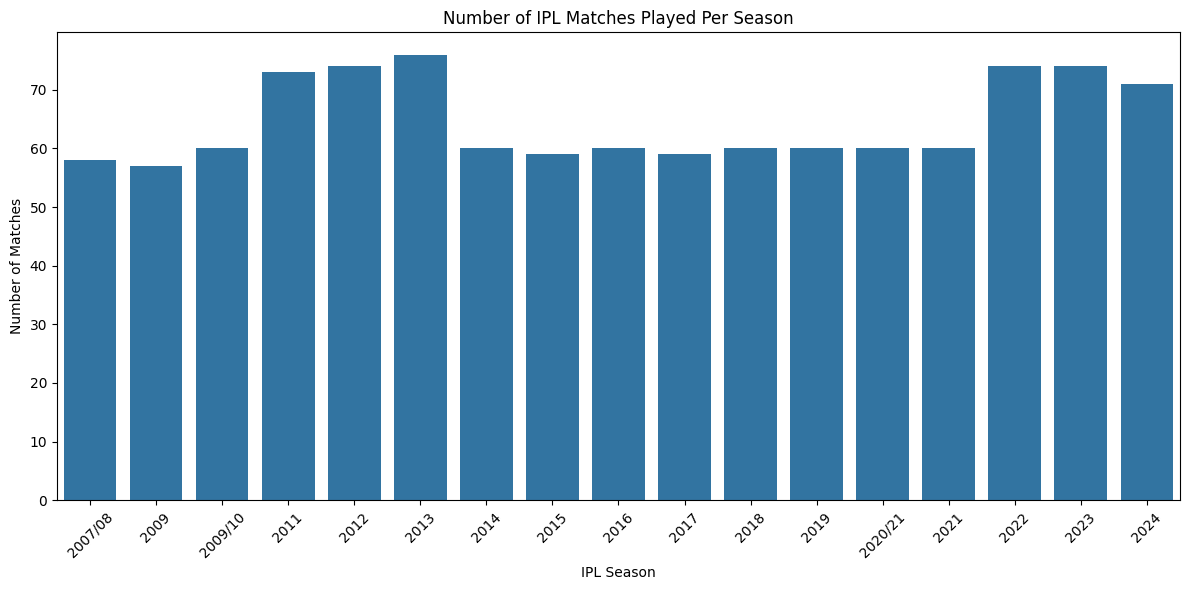

In [9]:
# Number of matches played in each season

plt.figure(figsize=(12, 6))

season_matches = matches['season'].value_counts().sort_index()

sns.barplot(
    x=season_matches.index,
    y=season_matches.values
)

plt.title('Number of IPL Matches Played Per Season')
plt.xlabel('IPL Season')
plt.ylabel('Number of Matches')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Observation

The bar chart shows the number of matches played in each IPL season. It helps us identify seasons with more matches and understand changes in the tournament format over time.

## 5. Team Performance Analysis

In this section, we analyze the performance of different IPL teams based on the number of matches won.

A horizontal bar chart is used to compare team victories and identify the teams with the highest number of wins.

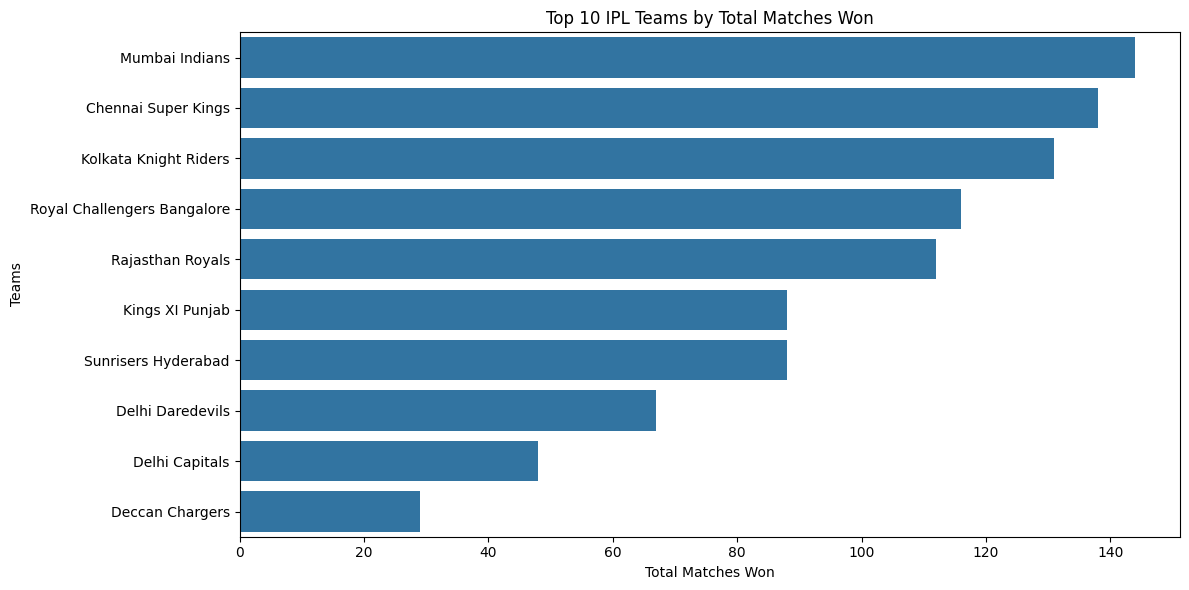

In [10]:
# Calculate total wins by each team

team_wins = matches['winner'].value_counts().head(10)

# Create bar chart
plt.figure(figsize=(12, 6))

sns.barplot(
    x=team_wins.values,
    y=team_wins.index
)

plt.title('Top 10 IPL Teams by Total Matches Won')
plt.xlabel('Total Matches Won')
plt.ylabel('Teams')

plt.tight_layout()
plt.show()

### Observation

The bar chart compares the top 10 IPL teams based on their total match victories.

The team with the longest bar has recorded the highest number of wins in the dataset. This helps us understand the historical performance of different IPL teams.

## 6. Toss Decision Analysis

The toss plays an important role in cricket matches. In this section, we analyze the decisions made by teams after winning the toss.

A pie chart is used to compare the percentage of teams choosing to bat first or field first.

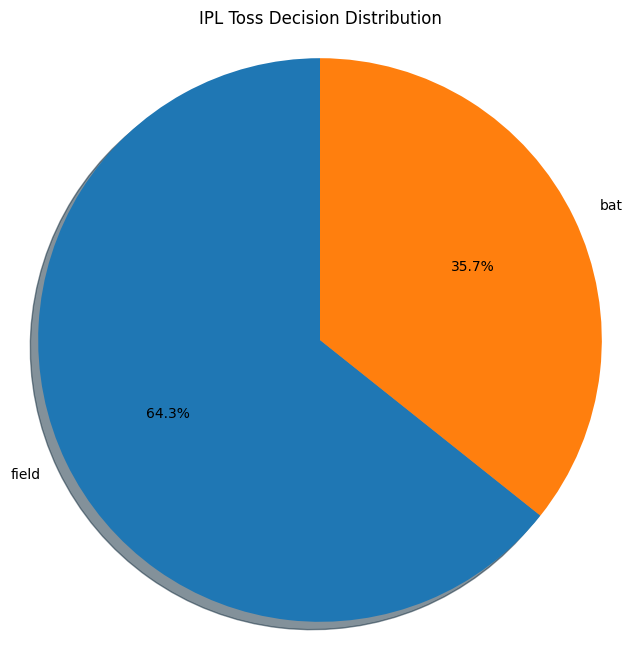

In [11]:
# Count toss decisions

toss_counts = matches['toss_decision'].value_counts()

# Create pie chart
plt.figure(figsize=(8, 8))

plt.pie(
    toss_counts,
    labels=toss_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    shadow=True
)

plt.title('IPL Toss Decision Distribution')
plt.axis('equal')
plt.show()

### Observation

The pie chart represents the percentage distribution of toss decisions.

It helps us understand whether teams prefer batting first or fielding first after winning the toss.

## 7. First Innings vs Second Innings Run Analysis

In this section, we compare the total runs scored in the first and second innings of IPL matches.

A scatter plot is used to understand the relationship between first-innings and second-innings scores and identify scoring patterns.

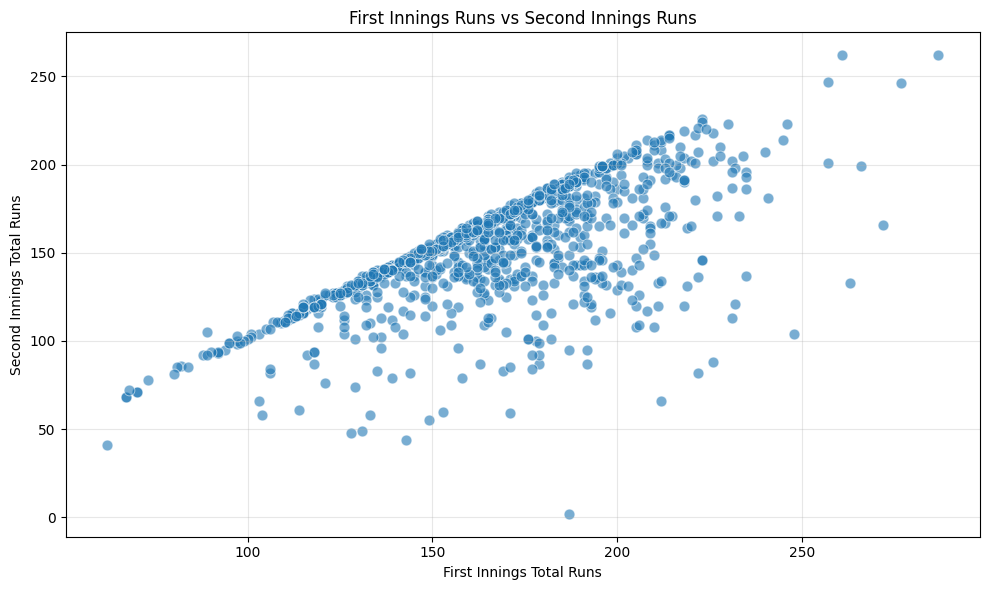

In [12]:
# Calculate total runs for each match and innings

innings_runs = deliveries.groupby(
    ['match_id', 'inning']
)['total_runs'].sum().unstack()

# Keep matches having both innings
innings_runs = innings_runs.dropna(subset=[1, 2])

# Create scatter plot
plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=innings_runs[1],
    y=innings_runs[2],
    alpha=0.6,
    s=60
)

plt.title('First Innings Runs vs Second Innings Runs')
plt.xlabel('First Innings Total Runs')
plt.ylabel('Second Innings Total Runs')
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Observation

The scatter plot compares the scores of the first and second innings.

Each point represents one match. The graph helps identify the relationship between first-innings and second-innings scores and shows how scoring patterns vary across matches.

## 8. Distribution of Runs in IPL Matches

In this section, we analyze the distribution of runs scored in individual deliveries.

A histogram is used to understand the frequency of different run values and identify the most common scoring outcomes.

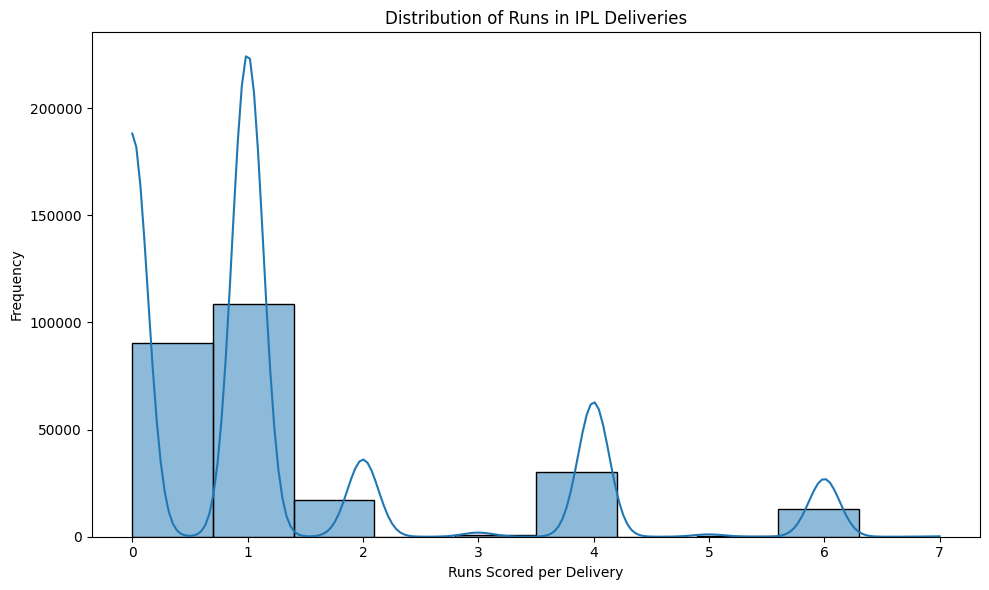

In [13]:
# Analyze total runs scored per delivery

plt.figure(figsize=(10, 6))

sns.histplot(
    data=deliveries,
    x='total_runs',
    bins=10,
    kde=True
)

plt.title('Distribution of Runs in IPL Deliveries')
plt.xlabel('Runs Scored per Delivery')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

### Observation

The histogram shows the frequency distribution of runs scored per delivery.

It helps us understand which run outcomes occur most frequently and how often higher-scoring deliveries take place.

## 9. Distribution of Total Runs by Innings

In this section, we compare the total runs scored in the first and second innings.

A box plot helps us understand the median, spread of scores, and unusually high or low scores in both innings.

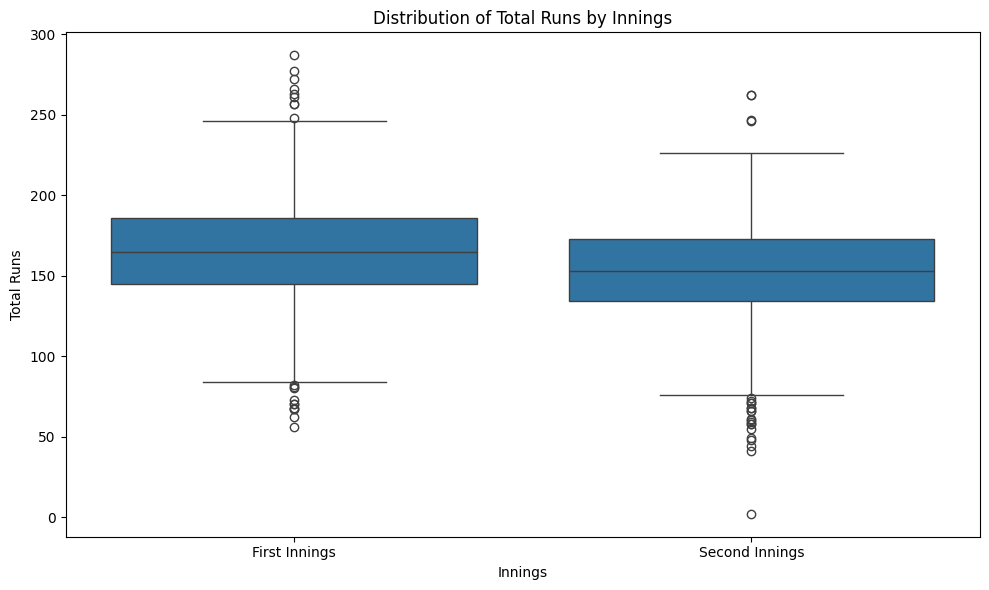

In [14]:
# Calculate total runs for each match and innings
innings_totals = deliveries.groupby(
    ['match_id', 'inning']
)['total_runs'].sum().reset_index()

# Keep only the first and second innings
innings_totals = innings_totals[
    innings_totals['inning'].isin([1, 2])
]

# Create the box plot
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=innings_totals,
    x='inning',
    y='total_runs'
)

plt.title('Distribution of Total Runs by Innings')
plt.xlabel('Innings')
plt.ylabel('Total Runs')

plt.xticks([0, 1], ['First Innings', 'Second Innings'])

plt.tight_layout()
plt.show()

### Observation

The box plot compares the scoring distribution of both innings.

It shows the median score, variation in runs, and possible outliers. This helps us understand how scoring patterns differ between the first and second innings.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load IPL datasets
matches = pd.read_csv("matches.csv")
deliveries = pd.read_csv("deliveries.csv")

# Display dataset information
print("IPL Matches Dataset:", matches.shape)
print("IPL Deliveries Dataset:", deliveries.shape)

print("\nMatches Columns:")
print(matches.columns.tolist())

print("\nDeliveries Columns:")
print(deliveries.columns.tolist())

IPL Matches Dataset: (1095, 20)
IPL Deliveries Dataset: (260920, 17)

Matches Columns:
['id', 'season', 'city', 'date', 'match_type', 'player_of_match', 'venue', 'team1', 'team2', 'toss_winner', 'toss_decision', 'winner', 'result', 'result_margin', 'target_runs', 'target_overs', 'super_over', 'method', 'umpire1', 'umpire2']

Deliveries Columns:
['match_id', 'inning', 'batting_team', 'bowling_team', 'over', 'ball', 'batter', 'bowler', 'non_striker', 'batsman_runs', 'extra_runs', 'total_runs', 'extras_type', 'is_wicket', 'player_dismissed', 'dismissal_kind', 'fielder']


In [ ]:
matches = pd.read_csv("matches.csv")
deliveries = pd.read_csv("deliveries.csv")

# Display dataset information
print("IPL Matches Dataset:", matches.shape)
print("IPL Deliveries Dataset:", deliveries.shape)

print("\nMatches Columns:")
print(matches.columns.tolist())

print("\nDeliveries Columns:")
print(deliveries.columns.tolist())

# 10. Conclusion

In this project, we performed Exploratory Data Analysis (EDA) on IPL cricket data using Python.

We used Pandas and NumPy for data analysis and Matplotlib and Seaborn for data visualization.

Through different graphs, we explored IPL seasons, team performance, toss decisions, innings scores, and scoring patterns.

This project helped us understand how data analysis and visualization can be used to find useful insights from cricket data.